In [74]:
# Summary table of BFB events across multiple OM2BFB output files for each sample.
import os
import glob
import pandas as pd
import re

# Set your result folder path
RESULT_DIR = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/TP21-M598"
summary_rows = []

# Process all *_ans.txt files
for ans_file in glob.glob(os.path.join(RESULT_DIR, "*_ans.txt")):
    if "_Final" in ans_file:
        continue  # Skip Final_ans.txt files — we only want *_ans.txt

    sample_id = os.path.basename(ans_file).replace("_ans.txt", "")

    try:
        # Handle header starting with #
        with open(ans_file, 'r') as f:
            first_line = f.readline()
        if first_line.startswith("#"):
            header = first_line.lstrip("#").strip().split("\t")
            seg_df = pd.read_csv(ans_file, sep="\t", skiprows=1, names=header)
        else:
            seg_df = pd.read_csv(ans_file, sep="\t")

        # Normalize column names
        seg_df.columns = seg_df.columns.str.strip().str.lower()
        chrom = seg_df['chromosome'].iloc[0]
        start = int(seg_df['startpos'].iloc[0])
        end = int(seg_df['endpos'].iloc[0])
        cn = seg_df['cn'].iloc[0]

        # Load foldback file with header fix
        fb_file = os.path.join(RESULT_DIR, f"{sample_id}_foldback_coordinate.txt")
        if os.path.exists(fb_file):
            with open(fb_file, 'r') as f:
                fb_header = f.readline()
            if fb_header.startswith("#"):
                fb_cols = fb_header.lstrip("#").strip().split("\t")
                fb_df = pd.read_csv(fb_file, sep="\t", skiprows=1, names=fb_cols)
            else:
                fb_df = pd.read_csv(fb_file, sep="\t")
            fb_df.columns = fb_df.columns.str.strip().str.lower()
            fb_pos = int(fb_df['start'].iloc[0])
        else:
            fb_pos = "NA"

        # Load final score and structure
        structure = "NA"
        score = "NA"
        final_file = os.path.join(RESULT_DIR, f"{sample_id}_Final_ans.txt")
        if os.path.exists(final_file):
            final_df = pd.read_csv(final_file, sep="\t")
            final_df.columns = final_df.columns.str.strip().str.lower()
            if 'structure' in final_df.columns:
                structure = final_df['structure'].iloc[0]
            if 'finalscore' in final_df.columns:
                score = final_df['finalscore'].iloc[0]

        # Store result
        summary_rows.append({
            "Sample ID": sample_id,
            "Chromosome": chrom,
            "Start": start,
            "End": end,
            "CN": cn,
            "Foldback Site": fb_pos,
            "BFB Structure": structure,
            "Final Score": score
        })

    except Exception as e:
        print(f"⚠️ Error processing {sample_id}: {e}")

# Create DataFrame
summary_df = pd.DataFrame(summary_rows)

# Sort by numeric ID in 'ampliconX'
def extract_amplicon_number(sample_id):
    match = re.search(r'amplicon(\d+)', sample_id)
    return int(match.group(1)) if match else float('inf')

summary_df['SortKey'] = summary_df['Sample ID'].apply(extract_amplicon_number)
summary_df = summary_df.sort_values(by="SortKey").drop(columns=["SortKey"])

# Save sorted result
output_path = os.path.join(RESULT_DIR, "TP21-M598_summary_table.csv")
summary_df.to_csv(output_path, index=False)

print(f"\n✅ Summary table saved in order: {output_path}")



✅ Summary table saved in order: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/TP21-M598/TP21-M598_summary_table.csv


In [70]:
# Merge all BFB summary CSVs into one combined file
import os
import glob
import pandas as pd

# Set the parent directory containing all sample subfolders
BASE_DIR = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output"
OUTPUT_FILE = os.path.join(BASE_DIR, "Combined_BFB_summary_by_sample_amplicon.csv")

# Recursively find all *_BFB_summary_table.csv files in subfolders
csv_files = glob.glob(os.path.join(BASE_DIR, "**/*_BFB_summary_table.csv"), recursive=True)

all_dfs = []

for file in csv_files:
    # Sample ID from the filename
    sample_id = os.path.basename(file).replace("_BFB_summary_table.csv", "")

    # Read the CSV
    df = pd.read_csv(file)

    # Rename 'Sample ID' to 'Amplicon ID' if present
    if 'Sample ID' in df.columns:
        df = df.rename(columns={'Sample ID': 'Amplicon ID'})

    # Add Sample ID column from file/folder name
    df.insert(0, 'Sample ID', sample_id)

    all_dfs.append(df)

# Combine all into one DataFrame
combined_df = pd.concat(all_dfs, ignore_index=True)

# Optional: sort by Sample ID and Amplicon ID
combined_df = combined_df.sort_values(by=["Sample ID", "Amplicon ID"])

# Save output
combined_df.to_csv(OUTPUT_FILE, index=False)

print(f"✅ Combined summary saved to:\n{OUTPUT_FILE}")


✅ Combined summary saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon.csv


In [72]:
# Export BFB Regions to BED Format
import pandas as pd
import os

# Path to your combined BFB summary CSV
csv_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon.csv"
output_dir = os.path.dirname(csv_path)

# Load the combined BFB summary
df = pd.read_csv(csv_path)

# Ensure numeric types
df['Start'] = df['Start'].astype(int)
df['End'] = df['End'].astype(int)

# Create BED-formatted DataFrame
# BED is 0-based start, 1-based end (so Start stays as is)
bed_df = df[['Chromosome', 'Start', 'End']].copy()
bed_df['Name'] = df['Sample ID'] + "|" + df['Amplicon ID']

# Output BED file path
bed_path = os.path.join(output_dir, "Combined_BFB_summary_regions.bed")

# Save BED file (no header, tab-separated)
bed_df[['Chromosome', 'Start', 'End', 'Name']].to_csv(bed_path, sep="\t", index=False, header=False)

print(f"✅ BED file saved at: {bed_path}")


✅ BED file saved at: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_regions.bed


In [75]:
# Gene Names from GTF

import pandas as pd

# Load BFB-gene hits file (bedtools intersect output)
hits_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits.txt"  # update path
bfb_df = pd.read_csv(hits_path, sep="\t", header=None, names=[
    "BFB_chr", "BFB_start", "BFB_end", "sample_amplicon",
    "gene_chr", "gene_start", "gene_end", "gene_name", "score", "strand"
])

# Fill missing gene names with placeholder
bfb_df['gene_name'] = bfb_df['gene_name'].fillna("NA")

# Extract Sample/Amplicon ID
bfb_df[['Sample ID', 'Amplicon ID']] = bfb_df['sample_amplicon'].str.split('|', expand=True)

# Load GTF file and extract gene entries only
gtf_path = "/bgfs/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf"  # update path
gtf_genes = []

with open(gtf_path, 'r') as gtf:
    for line in gtf:
        if line.startswith("#") or "\tgene\t" not in line:
            continue
        parts = line.strip().split('\t')
        attr = parts[8]
        chrom = parts[0]
        start = int(parts[3])
        end = int(parts[4])
        strand = parts[6]
        gene_name = None

        for item in attr.split(";"):
            if 'gene_name' in item:
                gene_name = item.strip().split('"')[1]
                break

        gtf_genes.append({
            "gene_chr": chrom,
            "gene_start": start,
            "gene_end": end,
            "gene_name_gtf": gene_name,
            "strand": strand
        })

# Convert GTF to DataFrame
gtf_df = pd.DataFrame(gtf_genes)

# Merge based on coordinates where gene_name is missing
# We'll match chromosome, strand, and overlapping coordinates
def match_gene(row):
    if row['gene_name'] != "NA":
        return row['gene_name']  # keep existing
    candidates = gtf_df[
        (gtf_df['gene_chr'] == row['gene_chr']) &
        (gtf_df['strand'] == row['strand']) &
        (gtf_df['gene_start'] <= row['gene_end']) &
        (gtf_df['gene_end'] >= row['gene_start'])
    ]
    return candidates['gene_name_gtf'].iloc[0] if not candidates.empty else "NA"

# Apply matching
bfb_df['gene_name'] = bfb_df.apply(match_gene, axis=1)

# Final cleanup and save
final = bfb_df[[
    "Sample ID", "Amplicon ID",
    "BFB_chr", "BFB_start", "BFB_end",
    "gene_chr", "gene_start", "gene_end",
    "gene_name", "strand"
]].drop_duplicates()

output_file = hits_path.replace(".txt", "_parsed_summary_filled.csv")
final.to_csv(output_file, index=False)

print(f"✅ Final output with filled gene names saved to:\n{output_file}")

✅ Final output with filled gene names saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled.csv


In [79]:
# To Filter Oncogene Hits
import pandas as pd

# Step 1: Load your gene-annotated BFB results
bfb_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled.csv"
bfb_df = pd.read_csv(bfb_path)

# Step 2: Load COSMIC gene list (Census_all.csv)
cosmic_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Census_all.tsv"  # downloaded from COSMIC
cosmic_df = pd.read_csv(cosmic_path, sep='\t', engine='python')
print(cosmic_df.columns.tolist())

# Step 3: Filter for only oncogenes (Tier 1 or 2, or Role = "oncogene")
oncogenes = cosmic_df[
    cosmic_df['Role in Cancer'].str.contains("oncogene", case=False, na=False)
]['Gene Symbol'].unique()

# Step 4: Keep only BFB entries overlapping oncogenes
filtered_df = bfb_df[bfb_df['gene_name'].isin(oncogenes)].copy()

# Save filtered results
output_path = bfb_path.replace(".csv", "_oncogenes_only.csv")
filtered_df.to_csv(output_path, index=False)

print(f"✅ Filtered BFB hits with oncogenes saved to:\n{output_path}")


['Gene Symbol', 'Name', 'Entrez GeneId', 'Genome Location', 'Tier', 'Hallmark', 'Chr Band', 'Somatic', 'Germline', 'Tumour Types(Somatic)', 'Tumour Types(Germline)', 'Cancer Syndrome', 'Tissue Type', 'Molecular Genetics', 'Role in Cancer', 'Mutation Types', 'Translocation Partner', 'Other Germline Mut', 'Other Syndrome', 'Synonyms']
✅ Filtered BFB hits with oncogenes saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled_oncogenes_only.csv


In [90]:
# To Filter Tumor Suppressor Hits
import pandas as pd

# Step 1: Load your gene-annotated BFB results
bfb_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled.csv"
bfb_df = pd.read_csv(bfb_path)

# Step 2: Load COSMIC gene list (Census_all.tsv)
cosmic_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Census_all.tsv"
cosmic_df = pd.read_csv(cosmic_path, sep='\t', engine='python')

# Optional: preview available columns
print("COSMIC columns:", cosmic_df.columns.tolist())

# Step 3: Filter for tumor suppressor genes
tsg_genes = cosmic_df[
    cosmic_df['Role in Cancer'].str.contains("TSG", case=False, na=False)
]['Gene Symbol'].unique()

# Step 4: Keep only BFB entries overlapping tumor suppressors
filtered_df = bfb_df[bfb_df['gene_name'].isin(tsg_genes)].copy()

# Save filtered results
output_path = bfb_path.replace(".csv", "_tumor_suppressors_only.csv")
filtered_df.to_csv(output_path, index=False)

print(f"✅ Filtered BFB hits with tumor suppressor genes saved to:\n{output_path}")


COSMIC columns: ['Gene Symbol', 'Name', 'Entrez GeneId', 'Genome Location', 'Tier', 'Hallmark', 'Chr Band', 'Somatic', 'Germline', 'Tumour Types(Somatic)', 'Tumour Types(Germline)', 'Cancer Syndrome', 'Tissue Type', 'Molecular Genetics', 'Role in Cancer', 'Mutation Types', 'Translocation Partner', 'Other Germline Mut', 'Other Syndrome', 'Synonyms']
✅ Filtered BFB hits with tumor suppressor genes saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled_tumor_suppressors_only.csv


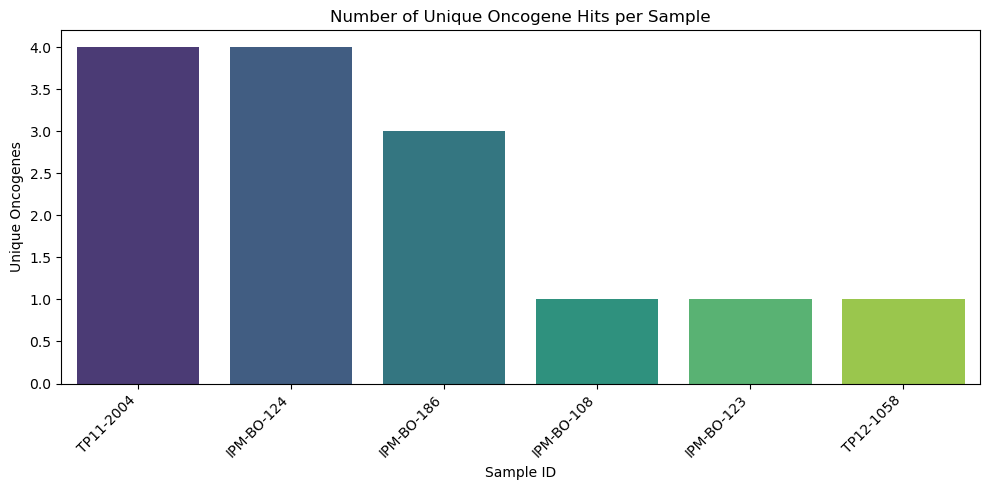

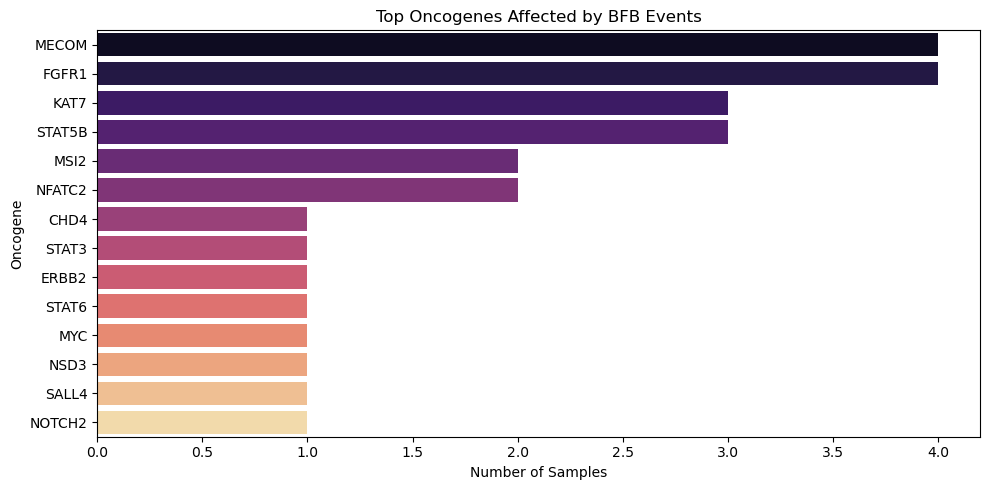

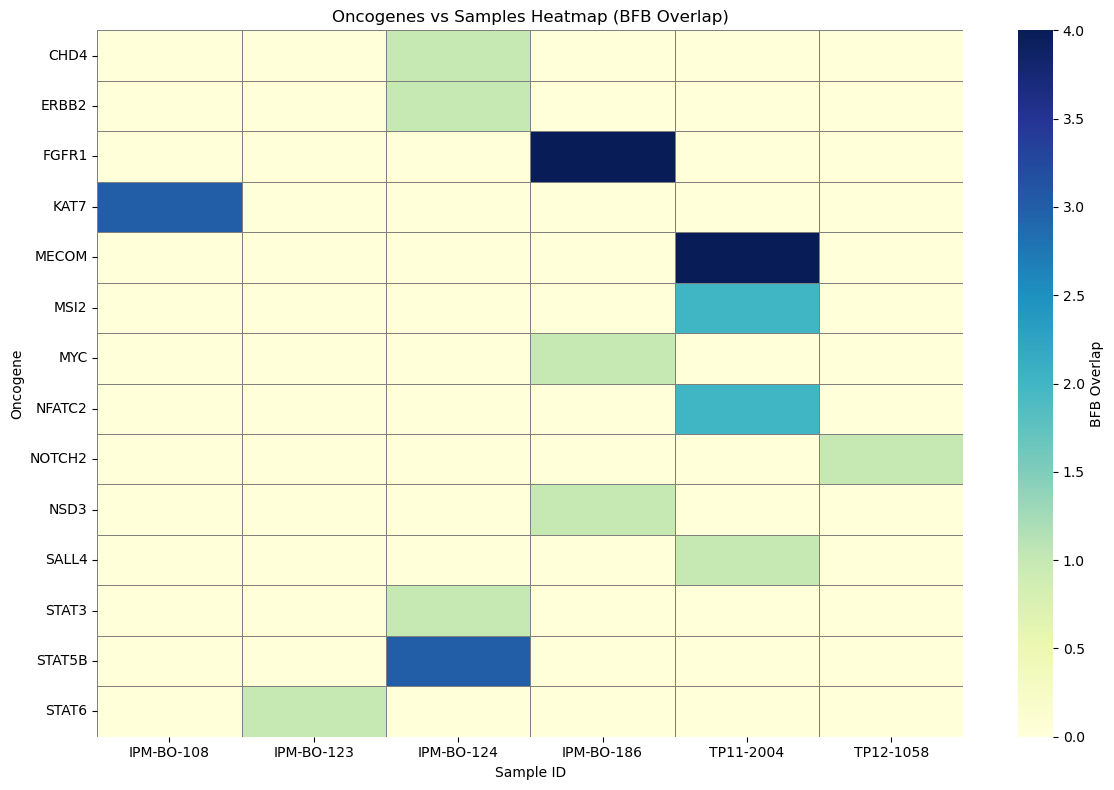

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the filtered BFB-oncogene file
df = pd.read_csv("/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_parsed_summary_filled_oncogenes_only.csv")

# 1️⃣ Oncogene count per sample
oncogene_counts = df.groupby("Sample ID")['gene_name'].nunique().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=oncogene_counts.index, y=oncogene_counts.values, palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Number of Unique Oncogene Hits per Sample")
plt.ylabel("Unique Oncogenes")
plt.xlabel("Sample ID")
plt.tight_layout()
plt.savefig("Oncogenes_per_sample.png")
plt.show()

# 2️⃣ Most frequent oncogene hits
top_oncogenes = df['gene_name'].value_counts().head(20)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_oncogenes.values, y=top_oncogenes.index, palette="magma")
plt.title("Top Oncogenes Affected by BFB Events")
plt.xlabel("Number of Samples")
plt.ylabel("Oncogene")
plt.tight_layout()
plt.savefig("Top_oncogenes_across_samples.png")
plt.show()

# 3️⃣ (Optional) Heatmap: Sample vs Oncogene
heatmap_data = df.pivot_table(index='gene_name', columns='Sample ID', aggfunc='size', fill_value=0)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", linewidths=0.5, linecolor='gray', cbar_kws={'label': 'BFB Overlap'})
plt.title("Oncogenes vs Samples Heatmap (BFB Overlap)")
plt.ylabel("Oncogene")
plt.xlabel("Sample ID")
plt.tight_layout()
plt.savefig("Oncogene_Sample_Heatmap.png")
plt.show()


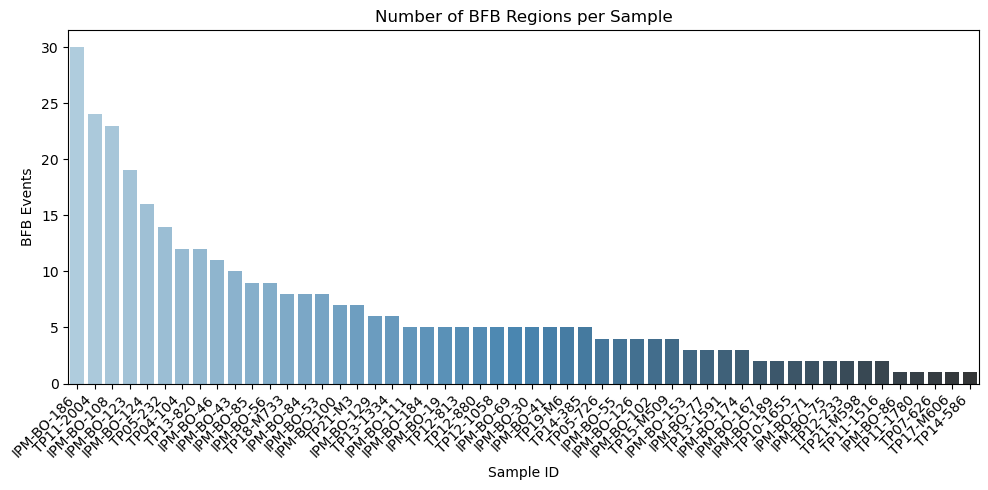

In [81]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon.csv")
counts = df['Sample ID'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values, palette='Blues_d')
plt.xticks(rotation=45, ha='right')
plt.title("Number of BFB Regions per Sample")
plt.ylabel("BFB Events")
plt.xlabel("Sample ID")
plt.tight_layout()
plt.show()


/scratch/slurm-5202644/ipykernel_61768/1172447181.py:3: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=df, x='Sample ID', y='Size', jitter=True, palette='viridis')


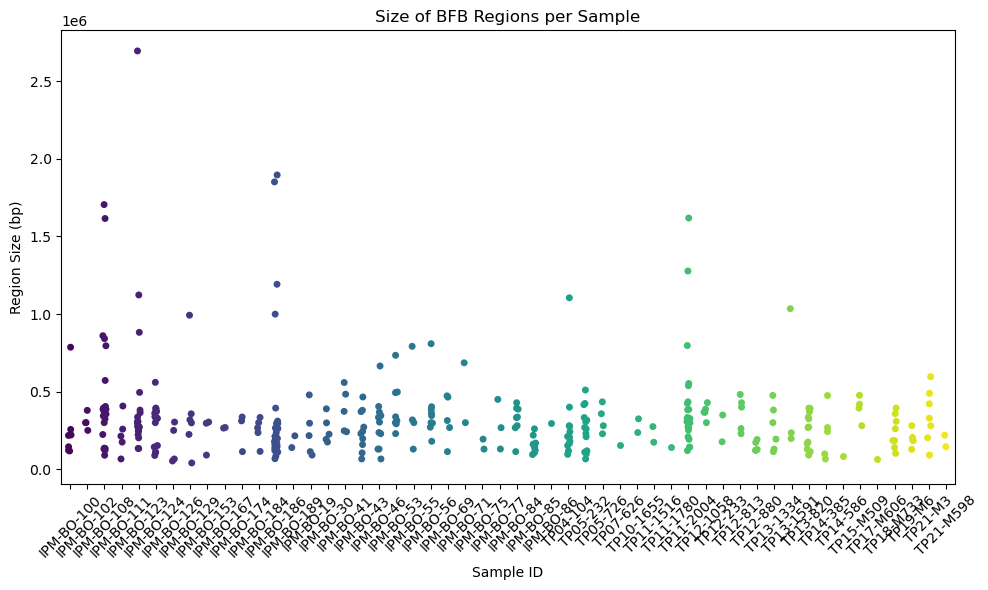

In [82]:
df['Size'] = df['End'] - df['Start']
plt.figure(figsize=(10, 6))
sns.stripplot(data=df, x='Sample ID', y='Size', jitter=True, palette='viridis')
plt.xticks(rotation=45)
plt.title("Size of BFB Regions per Sample")
plt.ylabel("Region Size (bp)")
plt.xlabel("Sample ID")
plt.tight_layout()
plt.show()


In [2]:
# Step 1: Export BFB Regions to BED Format
import pandas as pd
import os

# Path to your combined BFB summary CSV
csv_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_Tumor.csv"
output_dir = os.path.dirname(csv_path)

# Load the combined BFB summary
df = pd.read_csv(csv_path)

# Ensure numeric types
df['Start'] = df['Start'].astype(int)
df['End'] = df['End'].astype(int)

# Create BED-formatted DataFrame
# BED is 0-based start, 1-based end (so Start stays as is)
bed_df = df[['Chromosome', 'Start', 'End']].copy()
bed_df['Name'] = df['Sample ID'] + "|" + df['Amplicon ID']

# Output BED file path
bed_path = os.path.join(output_dir, "Combined_BFB_summary_regions_Tumor.bed")

# Save BED file (no header, tab-separated)
bed_df[['Chromosome', 'Start', 'End', 'Name']].to_csv(bed_path, sep="\t", index=False, header=False)

print(f"✅ BED file saved at: {bed_path}")

✅ BED file saved at: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_regions_Tumor.bed


In [8]:
import pandas as pd

# Load BFB-gene hits file (bedtools intersect output)
hits_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_IPM.txt"  # update path
bfb_df = pd.read_csv(hits_path, sep="\t", header=None, names=[
    "BFB_chr", "BFB_start", "BFB_end", "sample_amplicon",
    "gene_chr", "gene_start", "gene_end", "gene_name", "score", "strand"
])

# Fill missing gene names with placeholder
bfb_df['gene_name'] = bfb_df['gene_name'].fillna("NA")

# Extract Sample/Amplicon ID
bfb_df[['Sample ID', 'Amplicon ID']] = bfb_df['sample_amplicon'].str.split('|', expand=True)

# Load GTF file and extract gene entries only
gtf_path = "/bgfs/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf"  # update path
gtf_genes = []

with open(gtf_path, 'r') as gtf:
    for line in gtf:
        if line.startswith("#") or "\tgene\t" not in line:
            continue
        parts = line.strip().split('\t')
        attr = parts[8]
        chrom = parts[0]
        start = int(parts[3])
        end = int(parts[4])
        strand = parts[6]
        gene_name = None

        for item in attr.split(";"):
            if 'gene_name' in item:
                gene_name = item.strip().split('"')[1]
                break

        gtf_genes.append({
            "gene_chr": chrom,
            "gene_start": start,
            "gene_end": end,
            "gene_name_gtf": gene_name,
            "strand": strand
        })

# Convert GTF to DataFrame
gtf_df = pd.DataFrame(gtf_genes)

# Merge based on coordinates where gene_name is missing
# We'll match chromosome, strand, and overlapping coordinates
def match_gene(row):
    if row['gene_name'] != "NA":
        return row['gene_name']  # keep existing
    candidates = gtf_df[
        (gtf_df['gene_chr'] == row['gene_chr']) &
        (gtf_df['strand'] == row['strand']) &
        (gtf_df['gene_start'] <= row['gene_end']) &
        (gtf_df['gene_end'] >= row['gene_start'])
    ]
    return candidates['gene_name_gtf'].iloc[0] if not candidates.empty else "NA"

# Apply matching
bfb_df['gene_name'] = bfb_df.apply(match_gene, axis=1)

# Final cleanup and save
final = bfb_df[[
    "Sample ID", "Amplicon ID",
    "BFB_chr", "BFB_start", "BFB_end",
    "gene_chr", "gene_start", "gene_end",
    "gene_name", "strand"
]].drop_duplicates()

output_file = hits_path.replace(".txt", "_parsed_summary_filled.csv")
final.to_csv(output_file, index=False)

print(f"✅ Final output with filled gene names saved to:\n{output_file}")

✅ Final output with filled gene names saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_IPM_parsed_summary_filled.csv


In [11]:
# Step 1: Load your gene-annotated BFB results
bfb_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_Tumor_parsed_summary_filled.csv"
bfb_df = pd.read_csv(bfb_path)

# Step 2: Load COSMIC gene list (Census_all.csv)
cosmic_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Census_all.tsv"  # downloaded from COSMIC
cosmic_df = pd.read_csv(cosmic_path, sep='\t', engine='python')
print(cosmic_df.columns.tolist())

# Step 3: Filter for only oncogenes (Tier 1 or 2, or Role = "oncogene")
oncogenes = cosmic_df[
    cosmic_df['Role in Cancer'].str.contains("oncogene", case=False, na=False)
]['Gene Symbol'].unique()

# Step 4: Keep only BFB entries overlapping oncogenes
filtered_df = bfb_df[bfb_df['gene_name'].isin(oncogenes)].copy()

# Save filtered results
output_path = bfb_path.replace(".csv", "_oncogenes_only.csv")
filtered_df.to_csv(output_path, index=False)

print(f"✅ Filtered BFB hits with oncogenes saved to:\n{output_path}")

['Gene Symbol', 'Name', 'Entrez GeneId', 'Genome Location', 'Tier', 'Hallmark', 'Chr Band', 'Somatic', 'Germline', 'Tumour Types(Somatic)', 'Tumour Types(Germline)', 'Cancer Syndrome', 'Tissue Type', 'Molecular Genetics', 'Role in Cancer', 'Mutation Types', 'Translocation Partner', 'Other Germline Mut', 'Other Syndrome', 'Synonyms']
✅ Filtered BFB hits with oncogenes saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_Tumor_parsed_summary_filled_oncogenes_only.csv


In [13]:
# To Filter Tumor Suppressor Hits
import pandas as pd

# Step 1: Load your gene-annotated BFB results
bfb_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_IPM_parsed_summary_filled.csv"
bfb_df = pd.read_csv(bfb_path)

# Step 2: Load COSMIC gene list (Census_all.tsv)
cosmic_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Census_all.tsv"
cosmic_df = pd.read_csv(cosmic_path, sep='\t', engine='python')

# Optional: preview available columns
print("COSMIC columns:", cosmic_df.columns.tolist())

# Step 3: Filter for tumor suppressor genes
tsg_genes = cosmic_df[
    cosmic_df['Role in Cancer'].str.contains("TSG", case=False, na=False)
]['Gene Symbol'].unique()

# Step 4: Keep only BFB entries overlapping tumor suppressors
filtered_df = bfb_df[bfb_df['gene_name'].isin(tsg_genes)].copy()

# Save filtered results
output_path = bfb_path.replace(".csv", "_tumor_suppressors_only.csv")
filtered_df.to_csv(output_path, index=False)

print(f"✅ Filtered BFB hits with tumor suppressor genes saved to:\n{output_path}")


COSMIC columns: ['Gene Symbol', 'Name', 'Entrez GeneId', 'Genome Location', 'Tier', 'Hallmark', 'Chr Band', 'Somatic', 'Germline', 'Tumour Types(Somatic)', 'Tumour Types(Germline)', 'Cancer Syndrome', 'Tissue Type', 'Molecular Genetics', 'Role in Cancer', 'Mutation Types', 'Translocation Partner', 'Other Germline Mut', 'Other Syndrome', 'Synonyms']
✅ Filtered BFB hits with tumor suppressor genes saved to:
/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/BFB_gene_hits_IPM_parsed_summary_filled_tumor_suppressors_only.csv


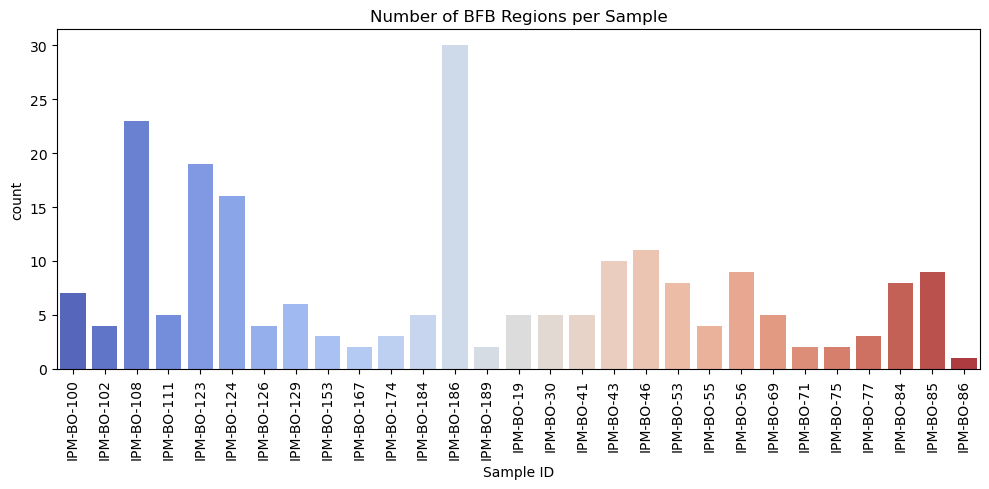

In [15]:
# plot
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your combined BFB summary file
df = pd.read_csv("/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_IPM.csv")

# Make sure 'Chromosome' is string and starts with 'chr'
df['Chromosome'] = df['Chromosome'].astype(str)
df['Chromosome'] = df['Chromosome'].apply(lambda x: f'chr{x}' if not x.startswith('chr') else x)

# Create a new column for region size
df['Region Size (bp)'] = df['End'] - df['Start']

# 🔹 1. Number of BFB events per sample
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Sample ID', palette='coolwarm')
plt.title("Number of BFB Regions per Sample")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("bfb_counts_per_sample.png")
plt.show()

Samples with BFB + amplicons:
BFB Class
BFB -    211
BFB +      5
Name: count, dtype: int64
['IPM-BO-108' 'IPM-BO-123' 'IPM-BO-186' 'IPM-BO-53']


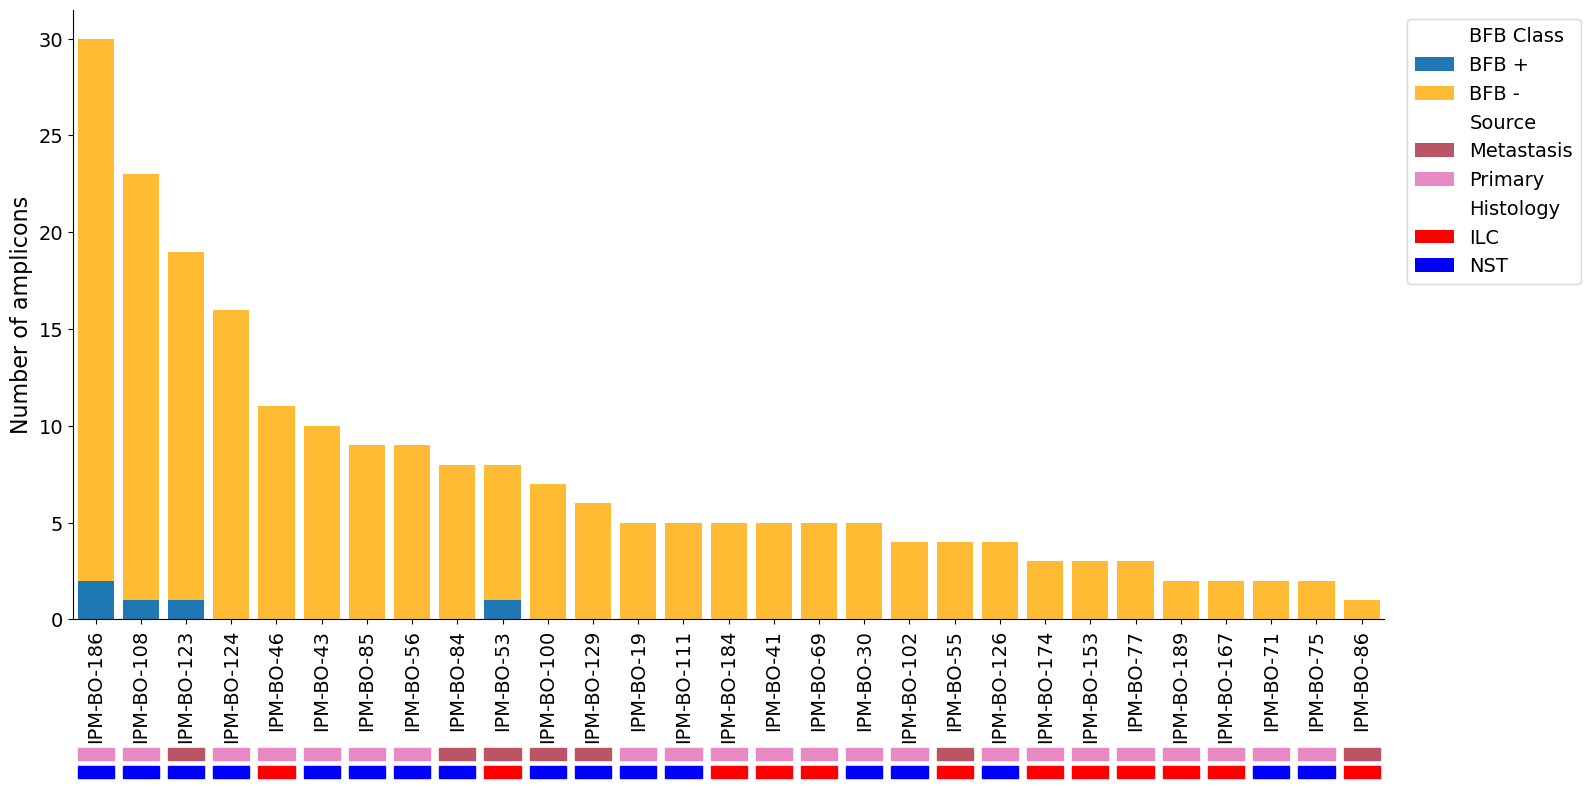

 Amplicon_counts_per_sample_annotated_bars_IPM saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Amplicon_counts_per_sample_annotated_bars_IPM.png


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import os

# === Load dataset ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_IPM.csv"
df = pd.read_csv(csv_path)
output_dir = os.path.dirname(csv_path)

plt.rcParams.update({
    "font.family": "DejaVu Sans",   # or 'Arial', 'Times New Roman'
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# === Clean and classify BFB status ===
df['Final Score'] = pd.to_numeric(df['Final Score'], errors='coerce')
df['BFB Class'] = df['Final Score'].apply(lambda x: 'BFB +' if x < 1.8 else 'BFB -')

# Filter rows with BFB +
bfb_positive_df = df[df['BFB Class'] == 'BFB +']
bfb_positive_samples = bfb_positive_df['Sample ID'].unique()

print("Samples with BFB + amplicons:")
print(df['BFB Class'].value_counts())
print(bfb_positive_samples)

# === Color maps ===
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF0000", "NST": "#0000FF"}

# === Compute BFB counts for sorting ===
count_df = df['Sample ID'].value_counts().reset_index()
count_df.columns = ['Sample ID', 'BFB Count']

# === Merge metadata for annotations ===
metadata_df = df[['Sample ID', 'Source', 'Histology']].drop_duplicates()
count_df = count_df.merge(metadata_df, on='Sample ID', how='left')
count_df = count_df.sort_values(by='BFB Count', ascending=False).reset_index(drop=True)

# === Prepare stacked BFB class counts per sample ===
stacked_df = df.groupby(['Sample ID', 'BFB Class']).size().unstack(fill_value=0)
stacked_df = stacked_df.loc[count_df['Sample ID']]  # match sample order

# === Plot setup ===
fig, ax = plt.subplots(figsize=(16, 8))

bar_colors = {
    'BFB +': '#1f77b4',  # Blue
    'BFB -': '#ffbb33'   # Orange/Yellow
}

bottom = None
for cls in ['BFB +', 'BFB -']:
    ax.bar(
        stacked_df.index,
        stacked_df[cls],
        bottom=bottom,
        label=cls,
        color=bar_colors[cls]
    )
    bottom = stacked_df[cls] if bottom is None else bottom + stacked_df[cls]
    
# === Title and axis ===
ax.set_ylabel("Number of amplicons", fontsize=16)
# Set X-axis tick positions and labels
ax.set_xticks(range(len(count_df)))  # positions: 0, 1, 2, ...
ax.set_xticklabels(count_df["Sample ID"], rotation=90, ha='center')  # labels: sample IDs

# Hide all X-axis ticks and labels (keep axis for annotation bars)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
ax.tick_params(axis='y', labelsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Add annotation bands under bars ===
bar_width = 0.8
bar_height = 0.02

for i, row in count_df.iterrows():
    source = row["Source"]
    hist = row["Histology"]
    x = i - bar_width / 2

    # Source band
    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, '#CCCCCC'),
        clip_on=False
    ))

    # Histology band
    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, '#888888'),
        clip_on=False
    ))

# === Legend setup ===
legend_elements = [
    Patch(facecolor='white', edgecolor='white', label='BFB Class'),
    Patch(facecolor=bar_colors['BFB +'], label='BFB +'),
    Patch(facecolor=bar_colors['BFB -'], label='BFB -'),
    Patch(facecolor='white', edgecolor='white', label='Source'),
] + [Patch(facecolor=color, label=label) for label, color in source_colors.items()] + [
    Patch(facecolor='white', edgecolor='white', label='Histology')
] + [Patch(facecolor=color, label=label) for label, color in histology_colors.items()]

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1))

# === Finalize ===
ax.set_xlim(-0.5, len(stacked_df) - 0.5)
plt.tight_layout()
output_path = os.path.join(output_dir, "Amplicon_counts_per_sample_annotated_bars_IPM.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f" Amplicon_counts_per_sample_annotated_bars_IPM saved to: {output_path}")


Samples with BFB + amplicons:
BFB Class
BFB -    129
BFB +      2
Name: count, dtype: int64
['TP18-M733' 'TP19-M6']


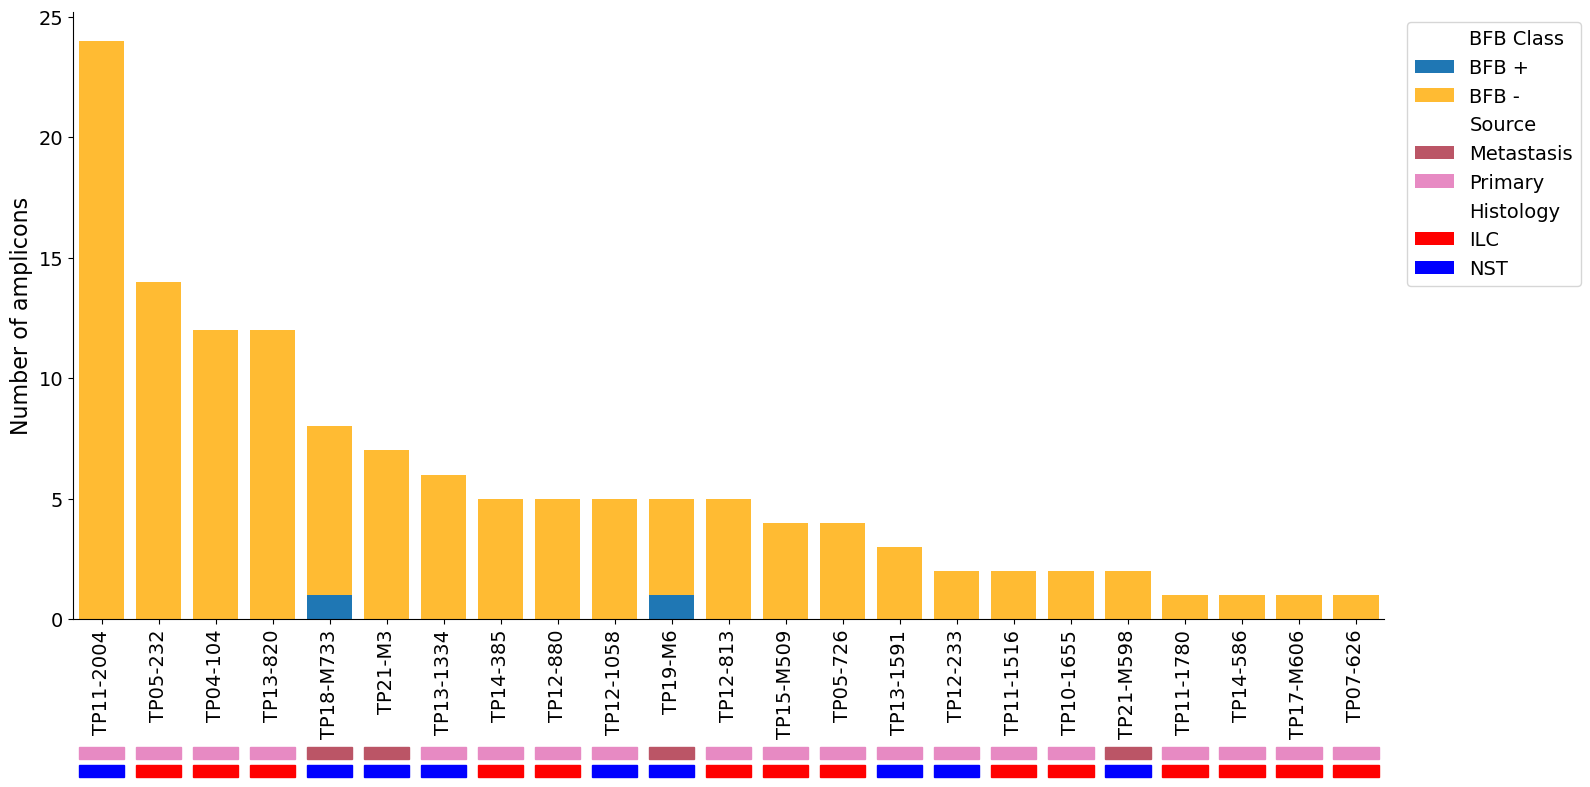

✅ Amplicon_counts_per_sample plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Amplicon_counts_per_sample_annotated_bars_Tumor.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import os

# === Load dataset ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_Tumor.csv"
df = pd.read_csv(csv_path)
output_dir = os.path.dirname(csv_path)

plt.rcParams.update({
    "font.family": "DejaVu Sans",   # or 'Arial', 'Times New Roman'
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# === Clean and classify BFB status ===
df['Final Score'] = pd.to_numeric(df['Final Score'], errors='coerce')  # handle invalid values safely
df['BFB Class'] = df['Final Score'].apply(lambda x: 'BFB +' if x < 1.8 else 'BFB -')

# Filter rows with BFB +
bfb_positive_df = df[df['BFB Class'] == 'BFB +']
bfb_positive_samples = bfb_positive_df['Sample ID'].unique()

print("Samples with BFB + amplicons:")
print(df['BFB Class'].value_counts())
print(bfb_positive_samples)

# === Color maps ===
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF0000", "NST": "#0000FF"}

# === Compute BFB counts ===
count_df = df['Sample ID'].value_counts().reset_index()
count_df.columns = ['Sample ID', 'BFB Count']

# === Merge metadata ===
metadata_df = df[['Sample ID', 'Source', 'Histology']].drop_duplicates()
count_df = count_df.merge(metadata_df, on='Sample ID', how='left')
count_df = count_df.sort_values(by='BFB Count', ascending=False).reset_index(drop=True)

# === Prepare data for stacked bar plot ===
stacked_df = df.groupby(['Sample ID', 'BFB Class']).size().unstack(fill_value=0)
stacked_df = stacked_df.loc[count_df['Sample ID']]  # preserve sample order

# === Plot setup ===
fig, ax = plt.subplots(figsize=(16, 8))

# Bar colors
bar_colors = {
    'BFB +': '#1f77b4',  # Blue
    'BFB -': '#ffbb33'   # Orange/Yellow
}

# Plot stacked bars
bottom = None
for cls in ['BFB +', 'BFB -']:
    ax.bar(
        stacked_df.index,
        stacked_df[cls],
        bottom=bottom,
        label=cls,
        color=bar_colors[cls]
    )
    bottom = stacked_df[cls] if bottom is None else bottom + stacked_df[cls]

# === Title and axis ===
ax.set_ylabel("Number of amplicons", fontsize=16)
# Set X-axis tick positions and labels
ax.set_xticks(range(len(count_df)))  # positions: 0, 1, 2, ...
ax.set_xticklabels(count_df["Sample ID"], rotation=90, ha='center')  # labels: sample IDs


# Hide all X-axis ticks and labels (keep axis for annotation bars)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
ax.tick_params(axis='y', labelsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Add stacked annotation bars ===
bar_width = 0.8
bar_height = 0.02

for i, row in count_df.iterrows():
    # Source (top band)
    ax.add_patch(plt.Rectangle(
        (i - bar_width / 2, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(row['Source'], '#CCCCCC'),
        clip_on=False
    ))
    # Histology (bottom band)
    ax.add_patch(plt.Rectangle(
        (i - bar_width / 2, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(row['Histology'], '#888888'),
        clip_on=False
    ))

# === Legend ===
legend_elements = []

# BFB Class Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='BFB Class'))
for label, color in bar_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

# Source Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='Source'))
for label, color in source_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

# Histology Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='Histology'))
for label, color in histology_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1))

# === Adjust layout ===
ax.set_xlim(-0.5, len(stacked_df) - 0.5)
plt.tight_layout()
output_path = os.path.join(output_dir, "Amplicon_counts_per_sample_annotated_bars_Tumor.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Amplicon_counts_per_sample plot saved to: {output_path}")
